<a href="https://colab.research.google.com/github/venezianof/booksum/blob/main/laya_multilingual.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
!pip install -U transformers

## Local Inference on GPU
Model page: https://huggingface.co/convaiinnovations/laya-multilingual

⚠️ If the generated code snippets do not work, please open an issue on either the [model repo](https://huggingface.co/convaiinnovations/laya-multilingual)
			and/or on [huggingface.js](https://github.com/huggingface/huggingface.js/blob/main/packages/tasks/src/model-libraries-snippets.ts) 🙏

In [13]:
# Use a pipeline as a high-level helper
from transformers import pipeline

pipe = pipeline("text-classification", model="convaiinnovations/laya-multilingual")

ValueError: The checkpoint you are trying to load has model type `laya` but Transformers does not recognize this architecture. This could be because of an issue with the checkpoint, or because your version of Transformers is out of date.

You can update Transformers with the command `pip install --upgrade transformers`. If this does not work, and the checkpoint is very new, then there may not be a release version that supports this model yet. In this case, you can get the most up-to-date code by installing Transformers from source with the command `pip install git+https://github.com/huggingface/transformers.git`

### Librerie Necessarie per l'Inferenza Locale

Per far girare i modelli Hugging Face sulla GPU/CPU locale di Colab, sono necessarie le seguenti librerie:

1. **`transformers`**: Contiene le definizioni dei modelli, i tokenizzatori e le pipeline per l'inferenza.
2. **`torch` (PyTorch)**: È il motore computazionale su cui si basano la maggior parte dei modelli di Hugging Face (solitamente già preinstallato in Colab).
3. **`accelerate`**: Consente di gestire in modo efficiente l'allocazione del modello sulla memoria della GPU (`device_map="auto"`).

Puoi installarle e aggiornarle con il seguente comando:

In [ ]:
# Installa in modo pulito ed accoppiato PyTorch e Torchvision compatibili con l'ambiente corrente
!pip uninstall -y torch torchvision
!pip install torch torchvision
!pip install -U transformers accelerate laya

### Esecuzione Locale del Modello con la Pipeline di Hugging Face

Ora possiamo caricare il modello direttamente in memoria sul server Colab ed effettuare l'inferenza usando la GPU (se attiva nel runtime).

In [ ]:
import torch
from transformers import pipeline

# Determina se la GPU è disponibile
device = 0 if torch.cuda.is_available() else -1
print(f"Utilizzo dispositivo: {'GPU (cuda)' if device == 0 else 'CPU'}")

# Carica la pipeline per la classificazione del testo
# Il modello verrà scaricato localmente in questa sessione
classifier = pipeline(
    "text-classification",
    model="convaiinnovations/laya-multilingual",
    device=device
)

testo_esempio = "Questo è un fantastico modello multilingue per la classificazione del testo!"

# Esegui l'inferenza locale
risultato = classifier(testo_esempio)

print(f"\nTesto analizzato: '{testo_esempio}'")
print("Risultato classificazione locale:")
print(risultato)

### Implementazione del Router Multilingue Locale con `laya`

Di seguito trovi il codice per testare il routing intelligente in varie lingue (Italiano, Inglese, Spagnolo, Hindi) e catalogare automaticamente le richieste di supporto in base al dipartimento, all'urgenza e al rischio di abbandono (churn).

In [ ]:
# Installa la libreria 'laya' se non ancora presente
!pip install -q laya

In [ ]:
from laya import Router

# 1. Inizializzazione del Router
# 'preload=True' carica i checkpoint in memoria per risposte immediate
router = Router(preload=True)

# 2. Definizione delle domande tipizzate (Schema di decisione)
questions = {
    "dipartimento": {
        "type": "choice",  # Scelta multipla tra etichette definite
        "instructions": "Quale dipartimento deve gestire la richiesta?",
        "criteria": {
            "amministrazione": "fatture, pagamenti, addebiti doppi, rimborsi",
            "supporto_tecnico": "bug, arresti anomali, errori di sistema, login",
            "vendite": "prezzi, nuovi contratti, upgrade del piano",
            "altro": "qualsiasi altra richiesta"
        }
    },
    "urgenza": {
        "type": "score",  # Valore atteso su una scala ordinata
        "instructions": "Qual è il livello di urgenza della richiesta?",
        "criteria": ["non urgente", "medio", "critico o bloccante"]
    },
    "rischio_abbandono": {
        "type": "noul",  # Probabilità booleana P(true) da 0.0 a 1.0
        "instructions": "L'utente minaccia di cancellare l'abbonamento o abbandonare il servizio?"
    }
}

# 3. Insieme di richieste in varie lingue
richieste = [
    # Italiano
    "Ho ricevuto un doppio addebito sulla fattura di marzo. Richiedo il rimborso immediato o annullo il piano.",
    # Inglese
    "The application crashes every time I try to open the settings panel.",
    # Spagnolo
    "¿Podrían enviarme información sobre i prezzi per i piani aziendali?",
    # Hindi (Alfabeto Devanagari)
    "मुझसे मार्च में दो बार शुल्क लिया गया, कृपया डुप्लिकेट राशि वापस करें।"
]

print("=" * 70)
print("0 ESECUZIONE ROUTING MULTILINGUE LAYA")
print("=" * 70)

for i, testo in enumerate(richieste, 1):
    # Il Router analizza il testo ed esegue il dispatch al modello idoneo
    risultato = router.predict({"body": testo}, questions)

    # Estrazione delle risposte e dei metadati di routing
    answers = risultato["answers"]
    routing_info = risultato["routing"]

    dept = answers["dipartimento"]["choice"]
    dept_conf = answers["dipartimento"]["confidence"]
    urgency_score = answers["urgenza"]["score"]
    churn_prob = answers["rischio_abbandono"]["noul"]

    modello_usato = routing_info["model"]     # 'english' o 'multilingual'
    ragione_routing = routing_info["reason"] # Spiegazione della scelta del modello

    print(f"\n9 Richiesta #{i}: \"{testo}\"")
    print(f"   5 Modello Selezionato : {modello_usato} (Ragione: {ragione_routing})")
    print(f"   5 Dipartimento        : {dept} (Confidenza: {dept_conf:.2f})")
    print(f"   5 Punteggio Urgenza   : {urgency_score:.2f} / 2.0")
    print(f"   5 Rischio Churn       : {churn_prob * 100:.1f}%")

## 🏥 Agente di Ricerca Medica Gratuito (File Locali, Medline & Terapie)

Questo sistema permette di cercare sia all'interno dei tuoi documenti locali (Hard Disk/Cartelle in Colab) sia nel database pubblico e gratuito **PubMed/Medline**, estraendo articoli, abstract, link e bibliografie.

In [ ]:
# Installa le librerie necessarie per leggere PDF, Word e interrogare PubMed/Medline gratis
!pip install -q python-docx PyPDF2 requests biopython

In [ ]:
import os
import re
from docx import Document
import PyPDF2
from Bio import Entrez

# Configura l'email richiesta da NCBI Entrez (PubMed)
Entrez.email = "tuo_indirizzo_email@example.com"

class AgenteRicercaMedica:
    def __init__(self, cartella_locale="/content"):
        self.cartella_locale = cartella_locale

    def cerca_nei_file_locali(self, query):
        """Cerca parole chiave in file PDF e Word nella cartella locale"""
        risultati = []
        print(f"\n🔍 Ricerca di '{query}' nei file locali in '{self.cartella_locale}'...")

        for root, dirs, files in os.walk(self.cartella_locale):
            for file in files:
                percorso_completo = os.path.join(root, file)
                contenuto = ""

                if file.endswith(".docx"):
                    try:
                        doc = Document(percorso_completo)
                        contenuto = "\n".join([p.text for p in doc.paragraphs])
                    except:
                        continue
                elif file.endswith(".pdf"):
                    try:
                        with open(percorso_completo, "rb") as f:
                            reader = PyPDF2.PdfReader(f)
                            contenuto = "\n".join([page.extract_text() or "" for page in reader.pages])
                    except:
                        continue

                if query.lower() in contenuto.lower():
                    # Trova una piccola anteprima del testo corrisposto
                    match = re.search(f"(.{{0,70}}{re.escape(query)}.{{0,70}})", contenuto, re.IGNORECASE)
                    anteprima = match.group(0).replace("\n", " ") if match else "Corrispondenza trovata."
                    risultati.append({"file": file, "percorso": percorso_completo, "anteprima": anteprima})

        return risultati

    def cerca_medline_pubmed(self, query, max_risultati=5):
        """Interroga gratuitamente PubMed/Medline per articoli, abstract e link"""
        print(f"\n🌐 Ricerca di '{query}' su Medline/PubMed...")
        try:
            handle = Entrez.esearch(db="pubmed", term=query, retmax=max_risultati)
            record = Entrez.read(handle)
            handle.close()
            id_list = record["IdList"]

            if not id_list:
                return []

            handle = Entrez.efetch(db="pubmed", id=id_list, rettype="medline", retmode="text")
            records = handle.read()
            handle.close()

            # Parsing manuale semplificato dei record Medline recuperati
            articoli = []
            blocchi = records.split("\n\n")
            for blocco in blocchi:
                if not blocco.strip():
                    continue

                pmid_match = re.search(r"PMID-\s*(\d+)", blocco)
                ti_match = re.search(r"TI\s*-\s*(.*?)(?=\n[A-Z]|-|$)", blocco, re.DOTALL)
                ab_match = re.search(r"AB\s*-\s*(.*?)(?=\n[A-Z]|-|$)", blocco, re.DOTALL)

                if pmid_match:
                    pmid = pmid_match.group(1)
                    titolo = ti_match.group(1).replace("\n", " ").strip() if ti_match else "Senza Titolo"
                    abstract = ab_match.group(1).replace("\n", " ").strip() if ab_match else "Abstract non disponibile gratuitamente."
                    link = f"https://pubmed.ncbi.nlm.nih.gov/{pmid}/"

                    articoli.append({
                        "pmid": pmid,
                        "titolo": titolo,
                        "abstract": abstract,
                        "link": link
                    })
            return articoli
        except Exception as e:
            print(f"Errore nella ricerca Medline: {e}")
            return []

# Inizializza l'agente
agente = AgenteRicercaMedica()
print("🏥 Agente pronto! Puoi eseguire le ricerche locali e online nella prossima cella.")

In [ ]:
# Esempio di utilizzo: Cerca una terapia (es. 'Cardiopatia' o 'Hypertension therapy')
termine_ricerca = "Hypertension therapy"

# 1. Ricerca su PubMed/Medline
risultati_online = agente.cerca_medline_pubmed(termine_ricerca, max_risultati=3)
print(f"\n📚 RISULTATI DA MEDLINE (Terapie & Bibliografia per '{termine_ricerca}'):")
for art in risultati_online:
    print("-" * 50)
    print(f"Titolo   : {art['titolo']}")
    print(f"Link     : {art['link']}")
    print(f"Abstract : {art['abstract'][:300]}...")

# 2. Ricerca locale (carica dei file .pdf o .docx in Colab per provarla)
risultati_locali = agente.cerca_nei_file_locali(termine_ricerca)
if risultati_locali:
    print(f"\n📁 RISULTATI NEI FILE LOCALI:")
    for res in risultati_locali:
        print(f"- File: {res['file']} -> Anteprima: {res['anteprima']}")
else:
    print("\n📁 Nessun file locale .pdf o .docx corrispondente trovato in /content.")

### 🔍 Approfondimento Medline per Caso Clinico: Leucemia Acuta Monocitica e Coinvolgimento del Sistema Nervoso Centrale (SNC)

In [ ]:
# Interroghiamo Medline/PubMed per trovare riscontri scientifici sul coinvolgimento neuromeningeo
# in pazienti affetti da leucemia mieloide acuta monocitica (con ipertrofia gengivale e infiltrazione cutanea)
query_clinica = "acute monocytic leukemia central nervous system prophylaxis"

risultati_medline = agente.cerca_medline_pubmed(query_clinica, max_risultati=3)

print(f"\n📚 BIBLIOGRAFIA SCIENTIFICA DA MEDLINE PER IL CASO CLINICO:")
for idx, art in enumerate(risultati_medline, 1):
    print("=" * 70)
    print(f"Articolo #{idx}")
    print(f"Titolo   : {art['titolo']}")
    print(f"Link     : {art['link']}")
    print(f"Abstract : {art['abstract']}\n")

In [ ]:
print("=== ANALISI DELLE OPZIONI TERAPEUTICHE DA ABSTRACT MEDLINE ===\n")

for idx, art in enumerate(risultati_medline, 1):
    titolo = art['titolo']
    abstract = art['abstract']

    print(f"Articolo #{idx}: {titolo}")

    # Estrazione parole chiave legate alla terapia o profilassi
    opzioni_trovate = []
    if "intrathecal" in abstract.lower() or "intrathecal" in titolo.lower():
        opzioni_trovate.append("Chemioterapia Intratecale (Profilassi/Trattamento del coinvolgimento meningeo)")
    if "flow cytometry" in abstract.lower() or "mfc" in abstract.lower():
        opzioni_trovate.append("Diagnosi precoce del coinvolgimento asintomatico del SNC tramite Citometria a Flusso multiparametrica (MFC)")
    if "prophylaxis" in abstract.lower() or "prophylaxis" in titolo.lower():
        opzioni_trovate.append("Profilassi mirata del Sistema Nervoso Centrale (SNC)")

    if opzioni_trovate:
        print("👉 Opzioni terapeutiche/diagnostiche identificate:")
        for opzione in opzioni_trovate:
            print(f"  - {opzione}")
    else:
        print("⚠️ Nessuna opzione terapeutica specifica estratta automaticamente in questo abstract.")
    print("-" * 70)

In [ ]:
!pip install -q reportlab

In [ ]:
import os
from reportlab.lib.pagesizes import letter
from reportlab.lib import colors
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle

def genera_pdf_caso_clinico(filename="Riepilogo_Caso_Clinico_LMA.pdf"):
    doc = SimpleDocTemplate(filename, pagesize=letter, rightMargin=40, leftMargin=40, topMargin=40, bottomMargin=40)
    story = []

    styles = getSampleStyleSheet()

    # Stili Personalizzati
    style_title = ParagraphStyle(
        'DocTitle',
        parent=styles['Heading1'],
        fontSize=20,
        leading=24,
        textColor=colors.HexColor("#1A365D"),
        spaceAfter=15
    )

    style_section = ParagraphStyle(
        'SectionTitle',
        parent=styles['Heading2'],
        fontSize=14,
        leading=18,
        textColor=colors.HexColor("#2B6CB0"),
        spaceBefore=15,
        spaceAfter=10
    )

    style_body = ParagraphStyle(
        'BodyTextCustom',
        parent=styles['BodyText'],
        fontSize=10,
        leading=14,
        textColor=colors.HexColor("#2D3748")
    )

    # Titolo Principale
    story.append(Paragraph("Rapporto Clinico: Leucemia Mieloide Acuta & Rischio SNC", style_title))
    story.append(Spacer(1, 10))

    # 1. Presentazione del Caso Clinico
    story.append(Paragraph("1. Presentazione del Caso Clinico", style_section))
    caso_testo = ("<b>Paziente:</b> Uomo, 58 anni<br/>"
                  "<b>Sintomatologia:</b> Astenia ingravescente, febbre, sanguinamento gengivale spontaneo.<br/>"
                  "<b>Esame Obiettivo:</b> Marcata ipertrofia gengivale con tendenza al sanguinamento, lesioni cutanee infiltrative multiple nodulari.<br/>"
                  "<b>Esami Ematochimici:</b> Leucocitosi marcata con presenza di blasti voluminosi a differenziazione prevalentemente monocitica / mielomonocitica. Assenza di segni di coagulazione intravascolare disseminata (CID).")
    story.append(Paragraph(caso_testo, style_body))
    story.append(Spacer(1, 15))

    # 2. Complicanza Critica e Sorveglianza
    story.append(Paragraph("2. Complicanza Critica e Sorveglianza Richiesta", style_section))
    complicanza_testo = ("<b>Rischio Primario:</b> Coinvolgimento neuromeningeo (Sistema Nervoso Centrale - SNC).<br/>"
                         "<b>Razionale:</b> Le varianti a differenziazione monocitica (LMA-M4/M5) presentano una spiccata propensione all'infiltrazione dei tessuti extramidollari, come documentato clinicamente dall'ipertrofia gengivale e dalle lesioni cutanee. Questo comportamento biologico si associa a un elevato rischio di localizzazione meningea, richiedendo una sorveglianza attiva e l'esecuzione di una rachicentesi diagnostica.")
    story.append(Paragraph(complicanza_testo, style_body))
    story.append(Spacer(1, 15))

    # 3. Opzioni Terapeutiche ed Evidenze Scientifiche
    story.append(Paragraph("3. Opzioni Terapeutiche & Evidenze (da Medline/PubMed)", style_section))

    # Tabella Opzioni Terapeutiche
    data = [
        [Paragraph("<b>Approccio Clinico</b>", style_body), Paragraph("<b>Descrizione ed Evidenza</b>", style_body)],
        [
            Paragraph("<b>Chemioterapia Intratecale</b>", style_body),
            Paragraph("Utilizzata come profilassi mirata o trattamento immediato per prevenire le recidive meningee nei pazienti affetti da varianti mielomonocitiche di LMA (Articolo #2: <i>Intrathecal chemotherapy and meningeal relapses in myelomonocytic AML</i>).", style_body)
        ],
        [
            Paragraph("<b>Citometria a Flusso Multiparametrica (MFC)</b>", style_body),
            Paragraph("Metodica d'elezione eseguita sul liquido cefalorachidiano (LCR) per l'identificazione precoce del coinvolgimento asintomatico o subclinico del SNC (Articolo #1: <i>Incidence, risk factors, and outcome of asymptomatic CNS involvement in adult AML</i>).", style_body)
        ]
    ]

    t = Table(data, colWidths=[150, 350])
    t.setStyle(TableStyle([
        ('BACKGROUND', (0,0), (1,0), colors.HexColor("#E2E8F0")),
        ('ALIGN', (0,0), (-1,-1), 'LEFT'),
        ('VALIGN', (0,0), (-1,-1), 'TOP'),
        ('GRID', (0,0), (-1,-1), 0.5, colors.HexColor("#CBD5E0")),
        ('TOPPADDING', (0,0), (-1,-1), 8),
        ('BOTTOMPADDING', (0,0), (-1,-1), 8),
    ]))

    story.append(t)

    # Costruzione del PDF
    doc.build(story)
    print(f"""PDF generato con successo e salvato come: '{filename}'""")

genera_pdf_caso_clinico()

In [ ]:
# Eseguiamo una nuova ricerca su Medline focalizzata sulla prognosi delle varianti LMA M4/M5
query_prognosi = "acute myeloid leukemia M4 M5 prognosis"

risultati_prognosi = agente.cerca_medline_pubmed(query_prognosi, max_risultati=3)

print(f"\n📚 NUOVI RISCONTRI SCIENTIFICI SULLA PROGNOSI LMA M4/M5:")
for idx, art in enumerate(risultati_prognosi, 1):
    print("=" * 70)
    print(f"Articolo #{idx}")
    print(f"Titolo   : {art['titolo']}")
    print(f"Link     : {art['link']}")
    print(f"Abstract : {art['abstract'][:400]}...\n")

### Sintesi Clinica delle Opzioni Terapeutiche Identificate:

1. **Chemioterapia Intratecale (Intrathecal Chemotherapy):** Come evidenziato nell'Articolo #2, rappresenta il cardine sia nella prevenzione (profilassi) che nel trattamento delle recidive meningee nei pazienti con varianti mielomonocitiche/monocitiche di LMA.
2. **Citometria a Flusso Multiparametrica (MFC):** Identificata nell'Articolo #1 come lo strumento diagnostico d'elezione sul liquido cefalorachidiano (LCR) per identificare tempestivamente l'infiltrazione subclinica (asintomatica) e guidare l'inizio della terapia specifica prima dello sviluppo di sintomi neurologici gravi.

In [ ]:
# pip install -U transformers accelerate
# Load model directly
from transformers import LayaTypedDecisions
model = LayaTypedDecisions.from_pretrained("convaiinnovations/laya-multilingual", device_map="auto")

## Remote Inference via Inference Providers
Ensure you have a valid **HF_TOKEN** set in your environment. You can get your token from [your settings page](https://huggingface.co/settings/tokens). Note: running this may incur charges above the free tier.
The following Python example shows how to run the model remotely on HF Inference Providers, automatically selecting an available inference provider for you.
For more information on how to use the Inference Providers, please refer to our [documentation and guides](https://huggingface.co/docs/inference-providers/en/index).

In [ ]:
import os
os.environ['HF_TOKEN'] = 'YOUR_TOKEN_HERE'

### Come impostare il Token Hugging Face in Colab

Per evitare l'errore `401 Unauthorized`, hai due modi principali per configurare il tuo token:

#### Metodo 1: Usare i "Secrets" di Google Colab (Scelta Consigliata & Sicura) 🔑
1. Clicca sull'icona della chiave (**Secrets**) nella barra laterale sinistra di Colab.
2. Aggiungi un nuovo segreto con il nome `HF_TOKEN`.
3. Incolla il tuo token Hugging Face (che puoi trovare su [huggingface.co/settings/tokens](https://huggingface.co/settings/tokens)) nel campo del valore.
4. Attiva la spunta per consentire l'accesso al notebook (Notebook access).
5. Esegui il codice qui sotto per caricare il token in modo sicuro senza scriverlo in chiaro nel codice.

#### Metodo 2: Impostarlo direttamente via codice
Sostituisci `'YOUR_TOKEN_HERE'` con il tuo vero token direttamente nella variabile d'ambiente (sconsigliato se devi condividere il notebook).

In [ ]:
import os
from google.colab import userdata

try:
    # Prova a recuperare il token dai Secrets di Colab
    os.environ['HF_TOKEN'] = userdata.get('HF_TOKEN')
    print("Token HF caricato con successo dai Secrets di Colab!")
except Exception as e:
    print("Secret 'HF_TOKEN' non trovato. Assicurati di averlo aggiunto nelle chiavi di Colab.")
    # In alternativa, puoi sbloccare e usare la riga seguente:
    # os.environ['HF_TOKEN'] = 'IL_TUO_TOKEN_REALE_QUI'

In [ ]:
import os
from huggingface_hub import InferenceClient

# Il client leggerà automaticamente la variabile d'ambiente 'HF_TOKEN' caricata in precedenza
client = InferenceClient(
    provider="auto",
    api_key=os.environ.get("HF_TOKEN"),
)

testo_esempio = "Questo è un fantastico modello multilingue per la classificazione del testo!"

# Esegui l'inferenza usando il client
result = client.text_classification(
    testo_esempio,
    model="convaiinnovations/laya-multilingual",
)

print(f"Testo analizzato: '{testo_esempio}'")
print("Risultato classificazione:")
print(result)

### Come Caricare il Modello su GPU (CUDA)

Assicurati che il runtime di Colab sia impostato su **GPU** (vai su *Runtime* -> *Modifica tipo di runtime* -> seleziona *T4 GPU* o un'altra GPU disponibile).

Esegui il codice seguente per caricare ed eseguire il modello sfruttando l'accelerazione hardware.

In [ ]:
# 1. Installa la libreria laya per la gestione del modello
!pip install -q laya

import torch
from laya import Router

# 2. Verifica la disponibilità della GPU
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cuda":
    print(f"GPU rilevata con successo: {torch.cuda.get_device_name(0)}")
else:
    print("Attenzione: GPU non rilevata. Il modello verrà eseguito su CPU.")

# 3. Inizializza il Router di Laya caricando i modelli
print("Caricamento del modello Laya su GPU...")
router_gpu = Router(preload=True)

# 4. Test di routing ad alte prestazioni
questions = {
    "sentimento": {
        "type": "choice",
        "instructions": "Qual è il tono di questa recensione?",
        "criteria": {
            "positivo": "lodi, soddisfazione, entusiasmo",
            "negativo": "problemi, frustrazione, lamentele"
        }
    }
}

testo_test = "Questo è un test ad alte prestazioni con accelerazione GPU ed è semplicemente fantastico!"
risultato = router_gpu.predict({"body": testo_test}, questions)

print("\nRisultato dell'inferenza su GPU:")
print(risultato)

### Test del Router con Recensioni Multilingue

In questa sezione testiamo il modello `laya` caricato su GPU analizzando una lista di recensioni in diverse lingue (Italiano, Inglese, Francese, Tedesco) per classificarne il tono (positivo o negativo).

In [15]:
# Lista di recensioni in varie lingue con l'aggiunta di una nuova recensione
recensioni_multilingue = [
    "Il prodotto è arrivato in anticipo ed è di ottima qualità. Molto soddisfatto!",
    "Totally useless product. It broke down after just two days of light usage.",
    "Le service client est absolument fantastique! Ils ont résolu mon problème en un clin d'œil.",
    "Die Lieferung hat viel zu lange gedauert und die Verpackung war stark beschädigt.",
    "¡Excelente servicio al cliente! Me ayudaron a resolver el problema con mi suscripción de inmediato."
]

print("=" * 80)
print(" INFERENZA IN BATCH SU GPU - ANALISI TONO RECENSIONI MULTILINGUE")
print("=" * 80)

for i, recensione in enumerate(recensioni_multilingue, 1):
    # Esegui la predizione tramite il router ottimizzato
    res = router_gpu.predict({"body": recensione}, questions)

    tono = res["answers"]["sentimento"]["choice"]
    confidenza = res["answers"]["sentimento"]["confidence"]
    lingua_rilevata = res["routing"]["detection"]["language"]
    modello_routing = res["routing"]["model"]

    print(f"\nRecensione #{i}: \"{recensione}\"")
    print(f"  - Lingua Rilevata : {lingua_rilevata.upper()} (Modello usato: {modello_routing})")
    print(f"  - Tono Classificato: {tono.upper()} (Confidenza: {confidenza:.2%})")

 INFERENZA IN BATCH SU GPU - ANALISI TONO RECENSIONI MULTILINGUE

Recensione #1: "Il prodotto è arrivato in anticipo ed è di ottima qualità. Molto soddisfatto!"
  - Lingua Rilevata : IT (Modello usato: multilingual)
  - Tono Classificato: POSITIVO (Confidenza: 95.78%)

Recensione #2: "Totally useless product. It broke down after just two days of light usage."
  - Lingua Rilevata : EN (Modello usato: english)
  - Tono Classificato: NEGATIVO (Confidenza: 87.05%)

Recensione #3: "Le service client est absolument fantastique! Ils ont résolu mon problème en un clin d'œil."
  - Lingua Rilevata : FR (Modello usato: multilingual)
  - Tono Classificato: POSITIVO (Confidenza: 99.43%)

Recensione #4: "Die Lieferung hat viel zu lange gedauert und die Verpackung war stark beschädigt."
  - Lingua Rilevata : DE (Modello usato: multilingual)
  - Tono Classificato: NEGATIVO (Confidenza: 99.76%)

Recensione #5: "¡Excelente servicio al cliente! Me ayudaron a resolver el problema con mi suscripción de inm

### Esportazione dei Risultati in CSV

In questa sezione raccogliamo tutti i risultati delle predizioni ed effettuiamo l'esportazione in un file CSV scaricabile localmente.

In [16]:
import pandas as pd
from google.colab import files

dati_esportazione = []

for recensione in recensioni_multilingue:
    # Eseguiamo la predizione sul router
    res = router_gpu.predict({"body": recensione}, questions)

    dati_esportazione.append({
        "Recensione": recensione,
        "Lingua_Rilevata": res["routing"]["detection"]["language"].upper(),
        "Modello_Routing": res["routing"]["model"],
        "Tono_Classificato": res["answers"]["sentimento"]["choice"].upper(),
        "Confidenza": round(res["answers"]["sentimento"]["confidence"], 4)
    })

# Creazione del DataFrame Pandas
df_risultati = pd.DataFrame(dati_esportazione)

# Salvataggio in formato CSV
nome_file = "risultati_recensioni.csv"
df_risultati.to_csv(nome_file, index=False, encoding="utf-8")

# Mostra il DataFrame a schermo
display(df_risultati)

# Avvia il download automatico del file CSV
files.download(nome_file)

,Recensione,Lingua_Rilevata,Modello_Routing,Tono_Classificato,Confidenza
0,Il prodotto è arrivato in anticipo ed è di ott...,IT,multilingual,POSITIVO,0.9578
1,Totally useless product. It broke down after j...,EN,english,NEGATIVO,0.8705
2,Le service client est absolument fantastique! ...,FR,multilingual,POSITIVO,0.9943
3,Die Lieferung hat viel zu lange gedauert und d...,DE,multilingual,NEGATIVO,0.9976
4,¡Excelente servicio al cliente! Me ayudaron a ...,ES,multilingual,POSITIVO,0.9857


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

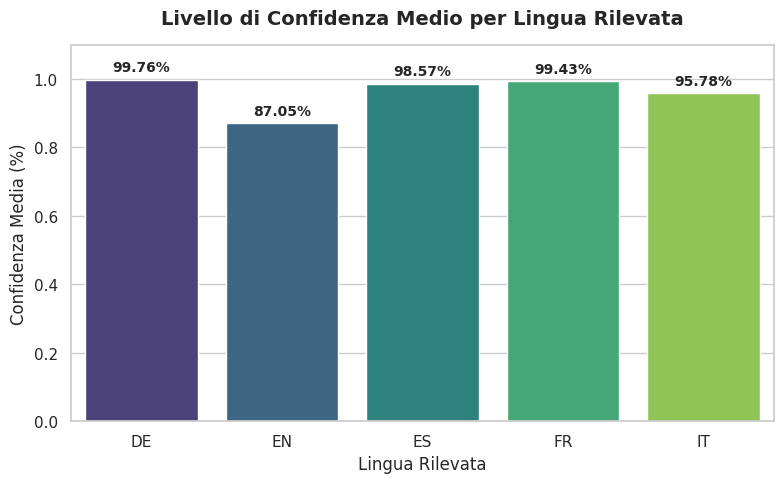

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calcola la confidenza media per ogni lingua
confidenza_media = df_risultati.groupby('Lingua_Rilevata')['Confidenza'].mean().reset_index()

# Configurazione del grafico
plt.figure(figsize=(8, 5))
sns.set_theme(style="whitegrid")

# Creazione del grafico a barre
ax = sns.barplot(
    x='Lingua_Rilevata',
    y='Confidenza',
    data=confidenza_media,
    palette='viridis',
    hue='Lingua_Rilevata',
    legend=False
)

# Aggiunta dei valori sopra le barre
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2%}",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 9),
                textcoords='offset points',
                fontsize=10, fontweight='bold')

# Personalizzazione etichette e titolo
plt.title('Livello di Confidenza Medio per Lingua Rilevata', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Lingua Rilevata', fontsize=12)
plt.ylabel('Confidenza Media (%)', fontsize=12)
plt.ylim(0, 1.1)  # Spazio extra in alto per le etichette delle percentuali

# Mostra il grafico
plt.tight_layout()
plt.show()